In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta

In [ ]:
# cleaned data

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

df = pd.read_csv("train.csv",
                 parse_dates=["pickup_datetime", "dropoff_datetime"])

print("Raw shape:", df.shape)
print(df.dtypes)
df.head()

Raw shape: (1458644, 11)
id                            object
vendor_id                      int64
pickup_datetime       datetime64[ns]
dropoff_datetime      datetime64[ns]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag            object
trip_duration                  int64
dtype: object


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982,40.768,-73.965,40.766,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980,40.739,-73.999,40.731,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979,40.764,-74.005,40.710,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010,40.720,-74.012,40.707,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973,40.793,-73.973,40.783,N,435


In [2]:

#Data cleaning
def haversine_np(lon1, lat1, lon2, lat2):
    """Great-circle distance in km between two points (decimal degrees)."""
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6367 * c

#Pre-cleaning diagnostics
df["distance_km"] = haversine_np(df.pickup_longitude, df.pickup_latitude,
                                 df.dropoff_longitude, df.dropoff_latitude)
df["speed_kmh"] = df["distance_km"] / (df["trip_duration"] / 3600)

print(df[["trip_duration", "distance_km", "speed_kmh"]].describe(percentiles=[.01, .5, .99]))
print("\nNegative/zero durations:", (df.trip_duration <= 0).sum())
print("Durations > 6 h     :", (df.trip_duration > 6 * 3600).sum())
print("Zero-distance trips :", (df.distance_km == 0).sum())
print("Speed > 100 km/h    :", (df.speed_kmh > 100).sum())
print("Speed < 1 km/h      :", (df.speed_kmh < 1).sum())
print("Pickup outside NYC  :",
      ((~df.pickup_longitude.between(-74.3, -73.7)) |
       (~df.pickup_latitude.between(40.5, 41.0))).sum())
print("\npassenger_count distribution:\n", df.passenger_count.value_counts().sort_index())

#Show the effect of each filter
def summarize(name, mask):
    kept = mask.sum()
    print(f"{name:<38} kept {kept:>10,}  ({kept/len(df)*100:5.2f}%)")
    return mask

# 1. sensible duration: between 30 s and 6 h
m_dur  = df.trip_duration.between(30, 6 * 3600)
# 2. plausible average speed: between 1 and 100 km/h
m_spd  = df.speed_kmh.between(1, 100)
# 3. pickup and dropoff inside the NYC bounding box
m_box  = (df.pickup_longitude.between(-74.3, -73.7) &
          df.pickup_latitude .between(40.5, 41.0) &
          df.dropoff_longitude.between(-74.3, -73.7) &
          df.dropoff_latitude .between(40.5, 41.0))
# 4. non-zero distance (removes cancelled / GPS-stuck trips)
m_dist = df.distance_km > 0
# 5. valid passenger count
m_pass = df.passenger_count.between(1, 6)

print("\n--- Filter retention ---")
summarize("Duration 30 s – 6 h", m_dur)
summarize("Speed 1 – 100 km/h", m_spd)
summarize("Coordinates in NYC bbox", m_box)
summarize("Distance > 0", m_dist)
summarize("Passenger count 1–6", m_pass)

mask = m_dur & m_spd & m_box & m_dist & m_pass
df_clean = df.loc[mask].copy()

print("\nRows before cleaning:", f"{len(df):,}")
print("Rows after  cleaning:", f"{len(df_clean):,}",
      f"({len(df_clean)/len(df)*100:.2f}% retained)")

print("\nCleaned summary:")
print(df_clean[["trip_duration", "distance_km", "speed_kmh"]].describe())

       trip_duration   distance_km     speed_kmh
count  1,458,644.000 1,458,644.000 1,458,644.000
mean         959.492         3.439        14.414
std        5,237.432         4.294        14.968
min            1.000         0.000         0.000
1%            87.000         0.139         1.393
50%          662.000         2.092        12.784
99%        3,440.000        20.774        40.720
max    3,526,282.000     1,240.130     9,269.014

Negative/zero durations: 0
Durations > 6 h     : 2061
Zero-distance trips : 5897
Speed > 100 km/h    : 175
Speed < 1 km/h      : 13241
Pickup outside NYC  : 256

passenger_count distribution:
 passenger_count
0         60
1    1033540
2     210318
3      59896
4      28404
5      78088
6      48333
7          3
8          1
9          1
Name: count, dtype: int64

--- Filter retention ---
Duration 30 s – 6 h                    kept  1,451,801  (99.53%)
Speed 1 – 100 km/h                     kept  1,445,228  (99.08%)
Coordinates in NYC bbox              

In [3]:

df_clean["pickup_date"]   = df_clean.pickup_datetime.dt.date
df_clean["pickup_hour"]   = df_clean.pickup_datetime.dt.hour
df_clean["pickup_dow"]    = df_clean.pickup_datetime.dt.dayofweek          # Mon=0 … Sun=6
df_clean["day_name"]      = df_clean.pickup_datetime.dt.day_name()
df_clean["is_weekend"]    = df_clean.pickup_dow >= 5
# (distance_km and speed_kmh were created before cleaning in Cell 1)

# sanity check
print(df_clean[["pickup_datetime","distance_km","trip_duration",
                "speed_kmh","pickup_dow","day_name","pickup_hour"]].head())

print("\nDay-of-week counts:")
print(df_clean.day_name.value_counts().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]))

      pickup_datetime  distance_km  trip_duration  speed_kmh  pickup_dow  \
0 2016-03-14 17:24:55        1.498            455     11.849           0   
1 2016-06-12 00:43:35        1.804            663      9.798           6   
2 2016-01-19 11:35:24        6.381           2124     10.815           1   
3 2016-04-06 19:32:31        1.485            429     12.458           2   
4 2016-03-26 13:30:55        1.188            435      9.830           5   

    day_name  pickup_hour  
0     Monday           17  
1     Sunday            0  
2    Tuesday           11  
3  Wednesday           19  
4   Saturday           13  

Day-of-week counts:
day_name
Monday       185308
Tuesday      200459
Wednesday    207871
Thursday     216049
Friday       220968
Saturday     218393
Sunday       192983
Name: count, dtype: int64


## 5. Airports

### Trips from ESB(Empire State Building) to airports

In [ ]:


# Coordinates: (latitude, longitude)
ESB = (40.756724, -73.983806)
JFK = (40.647929, -73.777813)
EWR = (40.689442, -74.173242)

# Calculate distance from each pickup to ESB
df_clean["esb_pickup_km"] = haversine_np(
    df_clean["pickup_longitude"],
    df_clean["pickup_latitude"],
    ESB[1], ESB[0]
)

# Calculate distance from each dropoff to JFK
df_clean["jfk_dropoff_km"] = haversine_np(
    df_clean["dropoff_longitude"],
    df_clean["dropoff_latitude"],
    JFK[1], JFK[0]
)

# Calculate distance from each dropoff to Newark
df_clean["ewr_dropoff_km"] = haversine_np(
    df_clean["dropoff_longitude"],
    df_clean["dropoff_latitude"],
    EWR[1], EWR[0]
)

# Choose our starting radii
ESB_RADIUS = 0.5
AIRPORT_RADIUS = 2.0

# Trips starting near Empire State Building
from_esb = df_clean["esb_pickup_km"] <= ESB_RADIUS

# Find trips going from ESB to each airport
jfk_trips = df_clean[
    from_esb &
    (df_clean["jfk_dropoff_km"] <= AIRPORT_RADIUS)
].copy()

ewr_trips = df_clean[
    from_esb &
    (df_clean["ewr_dropoff_km"] <= AIRPORT_RADIUS)
].copy()

# Convert travel time from seconds to minutes
jfk_trips["travel_minutes"] = jfk_trips["trip_duration"] / 60
ewr_trips["travel_minutes"] = ewr_trips["trip_duration"] / 60

# Display results
print("ESB to JFK:")
print("Number of trips:", len(jfk_trips))
print("Average minutes:", round(jfk_trips["travel_minutes"].mean(), 2))

print("\nESB to Newark:")
print("Number of trips:", len(ewr_trips))
print("Average minutes:", round(ewr_trips["travel_minutes"].mean(), 2))


ESB to JFK:
Number of trips: 863
Average minutes: 49.44

ESB to Newark:
Number of trips: 236
Average minutes: 36.28


### Test different radii

In [ ]:

 

def test_radii(esb_radius, airport_radius):
    for airport, col in [
        ("JFK", "jfk_dropoff_km"),
        ("Newark", "ewr_dropoff_km")
    ]:
        trips = df_clean[
            (df_clean["esb_pickup_km"] <= esb_radius) &
            (df_clean[col] <= airport_radius)
        ]

        avg = trips["trip_duration"].mean() / 60

        print(
            f"{airport}: {len(trips)} trips, "
            f"average = {avg:.2f} minutes"
        )

# Test different ESB radii
print("TEST 1: Changing ESB radius")
for radius in [0.3, 0.5, 0.8]:
    print(f"\nESB radius = {radius} km")
    test_radii(radius, 2.0)

# Test different airport radii
print("\nTEST 2: Changing airport radius")
for radius in [1.0, 2.0, 3.0]:
    print(f"\nAirport radius = {radius} km")
    test_radii(0.5, radius)


TEST 1: Changing ESB radius

ESB radius = 0.3 km
JFK: 365 trips, average = 49.26 minutes
Newark: 99 trips, average = 36.39 minutes

ESB radius = 0.5 km
JFK: 863 trips, average = 49.44 minutes
Newark: 236 trips, average = 36.28 minutes

ESB radius = 0.8 km
JFK: 2006 trips, average = 49.67 minutes
Newark: 547 trips, average = 37.11 minutes

TEST 2: Changing airport radius

Airport radius = 1.0 km
JFK: 541 trips, average = 48.79 minutes
Newark: 230 trips, average = 36.43 minutes

Airport radius = 2.0 km
JFK: 863 trips, average = 49.44 minutes
Newark: 236 trips, average = 36.28 minutes

Airport radius = 3.0 km
JFK: 917 trips, average = 49.38 minutes
Newark: 238 trips, average = 36.26 minutes


### Average travel time and number of trips by hour 

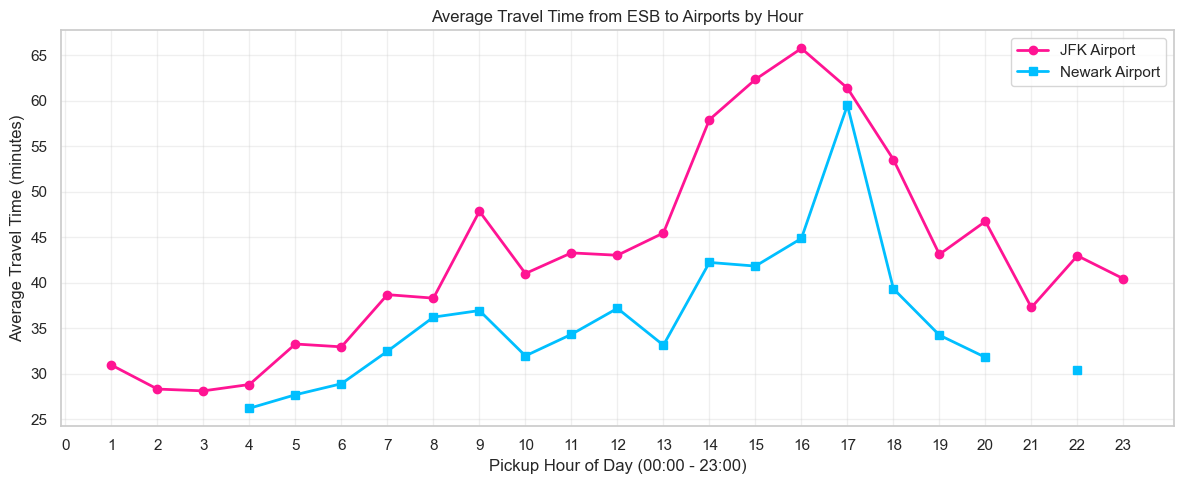

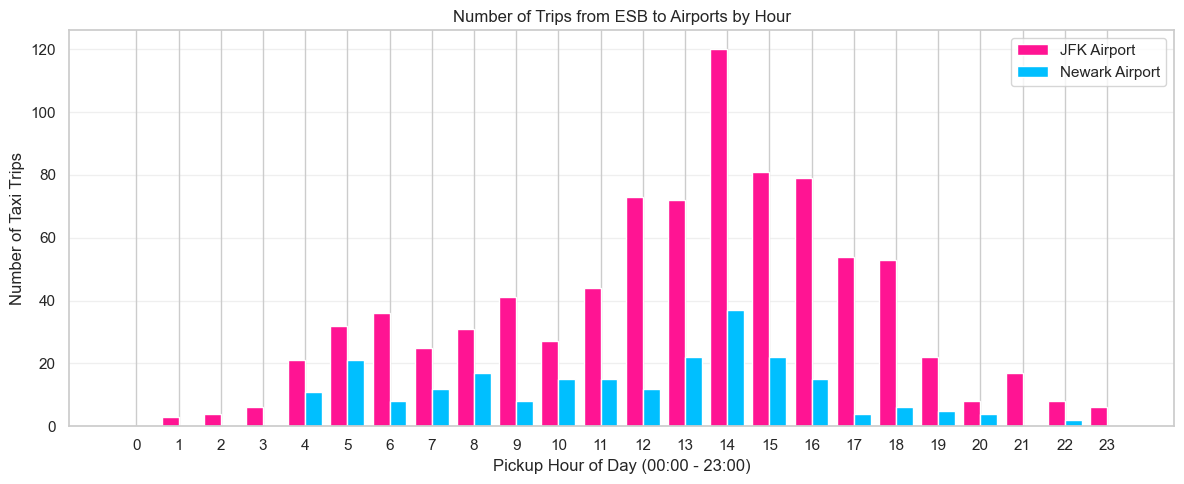

JFK hourly results:


,mean,count
pickup_hour,,
0,NaN,0.000
1,30.960,3.000
2,28.320,4.000
3,28.130,6.000
4,28.830,21.000
5,33.280,32.000
6,32.960,36.000
7,38.700,25.000
8,38.310,31.000


Newark hourly results:


,mean,count
pickup_hour,,
0,NaN,0.000
1,NaN,0.000
2,NaN,0.000
3,NaN,0.000
4,26.220,11.000
5,27.700,21.000
6,28.910,8.000
7,32.480,12.000
8,36.230,17.000


In [13]:



jfk_hourly = jfk_trips.groupby("pickup_hour")["travel_minutes"].agg(
    ["mean", "count"]
).reindex(range(24))

ewr_hourly = ewr_trips.groupby("pickup_hour")["travel_minutes"].agg(
    ["mean", "count"]
).reindex(range(24))

jfk_hourly["count"] = jfk_hourly["count"].fillna(0)
ewr_hourly["count"] = ewr_hourly["count"].fillna(0)

hours = np.arange(24)

plt.figure(figsize=(12, 5))

plt.plot(
    hours, jfk_hourly["mean"],
    marker="o", linewidth=2, label="JFK Airport", color='#FF1493'
)
plt.plot(
    hours, ewr_hourly["mean"],
    marker="s", linewidth=2, label="Newark Airport", color='#00BFFF'
)

plt.title("Average Travel Time from ESB to Airports by Hour")
plt.xlabel("Pickup Hour of Day (00:00 - 23:00)")
plt.ylabel("Average Travel Time (minutes)")
plt.xticks(hours)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



plt.figure(figsize=(12, 5))

width = 0.4

plt.bar(
    hours - width / 2,
    jfk_hourly["count"],
    width=width, label="JFK Airport", color='#FF1493'
)

plt.bar(
    hours + width / 2,
    ewr_hourly["count"],
    width=width, label="Newark Airport", color='#00BFFF'
)

plt.title("Number of Trips from ESB to Airports by Hour")
plt.xlabel("Pickup Hour of Day (00:00 - 23:00)")
plt.ylabel("Number of Taxi Trips")
plt.xticks(hours)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Display hourly data
print("JFK hourly results:")
display(jfk_hourly.round(2))

print("Newark hourly results:")
display(ewr_hourly.round(2))


### Airport Flags

In [14]:



# pickup distances to both airports
df_clean["jfk_pickup_km"] = haversine_np(
    df_clean["pickup_longitude"],
    df_clean["pickup_latitude"],
    JFK[1], JFK[0]
)

df_clean["ewr_pickup_km"] = haversine_np(
    df_clean["pickup_longitude"],
    df_clean["pickup_latitude"],
    EWR[1], EWR[0]
)

airport_flags = pd.DataFrame({
    "id": df_clean["id"],
    "near_jfk_pickup": df_clean["jfk_pickup_km"] <= 2.0,
    "near_jfk_dropoff": df_clean["jfk_dropoff_km"] <= 2.0,
    "near_ewr_pickup": df_clean["ewr_pickup_km"] <= 2.0,
    "near_ewr_dropoff": df_clean["ewr_dropoff_km"] <= 2.0
})

# True if a trip starts OR ends near either airport
flag_columns = [
    "near_jfk_pickup",
    "near_jfk_dropoff",
    "near_ewr_pickup",
    "near_ewr_dropoff"
]

airport_flags["airport_trip"] = (
    airport_flags[flag_columns].any(axis=1)
)

#airport_flags.to_csv("airport_flags.csv", index=False)

# Verify the output
print("Total trips:", len(airport_flags))
print("Airport-related trips:",
      airport_flags["airport_trip"].sum())

print("Duplicate IDs:", airport_flags["id"].duplicated().sum())

display(airport_flags.head())


Total trips: 1442031
Airport-related trips: 43680
Duplicate IDs: 0


,id,near_jfk_pickup,near_jfk_dropoff,near_ewr_pickup,near_ewr_dropoff,airport_trip
0,id2875421,False,False,False,False,False
1,id2377394,False,False,False,False,False
2,id3858529,False,False,False,False,False
3,id3504673,False,False,False,False,False
4,id2181028,False,False,False,False,False
